# NLP-Based Cybersecurity Incident Classification

**Goal:** use the words in a security-related message to predict its category.

**Public dataset:** [Multiclass NLP Dataset for Phishing and Social Engineering Threat Detection](https://doi.org/10.5281/zenodo.15235123). It contains 624 email/SMS-like messages labeled as Baiting, Malware, Phishing, Pretexting, Scareware, or NOT-Malicious General Class.

**Method:** clean text → split into training and test sets → turn words into TF-IDF numbers → train logistic regression → inspect results → try a new message. Run the cells in order in Google Colab. CICIDS contains network-flow features, so this text project uses the linked dataset instead.


In [ ]:
%pip -q install openpyxl

## 1. Load and inspect the messages

The spreadsheet has an unusual layout: most `Corpus` cells contain the message **and** its label separated by a tab; three messages continue into the `Labels` column. We combine the columns, then split off the label. Removing duplicate messages **before** the train/test split prevents identical text from appearing in both sets.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

url = 'https://zenodo.org/records/15235123/files/phishing_nlp_dataset.xlsx?download=1'
raw = pd.read_excel(url).fillna('')
combined = raw['Corpus'].astype(str) + ' ' + raw['Labels'].astype(str)
data = combined.str.rsplit('\t', n=1, expand=True)
data.columns = ['Corpus', 'Label']
data['Corpus'] = data['Corpus'].str.strip()
data['Label'] = data['Label'].str.strip()
data = data[(data['Corpus'] != '') & (data['Label'] != '')].drop_duplicates(subset='Corpus')

print(f'{len(data)} unique messages in {data.Label.nunique()} categories')
print(data['Label'].value_counts().to_string())
display(data.assign(Message=data['Corpus'].str.slice(0, 100))[['Message', 'Label']].head(5))


609 unique messages in 6 categories
Label
NOT-Malicious General Class    171
Phishing                       111
Scareware                      100
Baiting                         80
Malware                         77
Pretexting                      70


,Message,Label
0,"You have (1) package waiting, ready for delive...",Phishing
1,We were unable to deliver your package as ther...,Phishing
2,We are here to inform you that we need address...,Phishing
3,You have (1) message from us. Click below to o...,Phishing
4,You have (1) package awaiting delivery. Use yo...,Phishing


## 2. Train a text classifier

We reserve **20%** of messages for testing and keep the category proportions similar in both sets (`stratify`). TF-IDF gives more weight to informative words and two-word phrases; common English words are removed. Logistic regression learns which terms are associated with each category. The pipeline fits TF-IDF on training text only, so test text does not leak into training.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    data['Corpus'], data['Label'], test_size=0.2, stratify=data['Label'], random_state=42
)
model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words='english'),
    LogisticRegression(max_iter=1000, class_weight='balanced'),
)
model.fit(X_train, y_train)
print(f'Trained on {len(X_train)} messages; testing on {len(X_test)} unseen messages.')


Trained on 487 messages; testing on 122 unseen messages.


## 3. Evaluate the predictions

- **Precision:** when the model predicts a category, how often is it right?
- **Recall:** of the messages truly in that category, how many does it find?
- **F1-score:** a summary of precision and recall.
- **Support:** number of test messages in that category.

In the confusion matrix, **rows are actual categories** and **columns are predictions**. Diagonal cells are correct predictions; other cells show mistakes. “Benign” is a shorter display name for NOT-Malicious General Class.


                             precision    recall  f1-score   support

                    Baiting       1.00      0.88      0.93        16
                    Malware       1.00      0.88      0.93        16
NOT-Malicious General Class       0.85      1.00      0.92        34
                   Phishing       0.89      0.73      0.80        22
                 Pretexting       0.76      0.93      0.84        14
                  Scareware       0.95      0.90      0.92        20

                   accuracy                           0.89       122
                  macro avg       0.91      0.88      0.89       122
               weighted avg       0.90      0.89      0.89       122



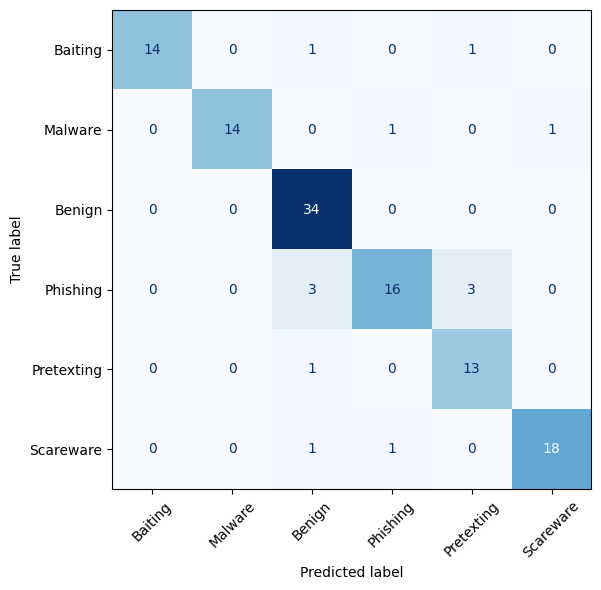

In [ ]:
predicted = model.predict(X_test)
print(classification_report(y_test, predicted, zero_division=0))
labels = sorted(data['Label'].unique())
short_labels = ['Benign' if label == 'NOT-Malicious General Class' else label for label in labels]
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, predicted, labels=labels, display_labels=short_labels,
    cmap='Blues', colorbar=False, xticks_rotation=45, ax=ax,
)
plt.tight_layout()
plt.show()


## 4. See which terms the model learned

For each category, these are the words or phrases with the largest positive model weights. They help explain the model's general behavior; they are **associations in this dataset**, not proof that a message is malicious.


In [ ]:
vectorizer = model.named_steps['tfidfvectorizer']
classifier = model.named_steps['logisticregression']
terms = vectorizer.get_feature_names_out()
top_terms = {
    label: ', '.join(terms[weights.argsort()[-6:][::-1]])
    for label, weights in zip(classifier.classes_, classifier.coef_)
}
display(pd.DataFrame({'Category': top_terms.keys(), 'Associated terms': top_terms.values()}))


,Category,Associated terms
0,Baiting,"free, offer free, offer, download use, use, ex..."
1,Malware,"file, view, contents, open, open file, attached"
2,NOT-Malicious General Class,"greetings, like, best, know, thank, really"
3,Phishing,"account, click, reset, money, account reset, c..."
4,Pretexting,"need, customer, representative, support, servi..."
5,Scareware,"download attachment, infected, download, compu..."


## 5. Try a message of your own

Change `new_message` and rerun this cell. The table shows the three categories the model favors most. These probabilities describe the model's estimate on this small dataset; they are not a guarantee about a real security incident.


In [ ]:
new_message = 'Your account is locked. Click this link and enter your password to restore access.'
scores = pd.Series(model.predict_proba([new_message])[0], index=classifier.classes_)
scores = scores.sort_values(ascending=False)
print('Predicted category:', scores.index[0])
display(scores.head(3).rename('Model probability').to_frame().round(3))


Predicted category: Phishing


,Model probability
Phishing,0.374
Malware,0.248
Baiting,0.132


## What this result means

This notebook classifies **security-related messages** within the six categories above. The dataset is small and some messages have similar wording, so the test score is a classroom baseline. Do not use it alone to triage live incidents or to classify incident types outside these categories.
